## Algorithm

In [1]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

## Experiment replication

Dataset information
-------------------
Shape: (1000, 6)
Normal observations: 950
Outliers: 50
Outlier proportion: 0.05

Running k = 5...

Running k = 20...

Running k = 45...

Running k = 100...


ROC AUC RESULTS

  k    LOF   RDOS    COF  kNN-LOF
  5 0.7881 0.7630 0.7930   0.7152
 20 0.8764 0.7948 0.7962   0.8424
 45 0.8654 0.7695 0.7650   0.8028
100 0.8127 0.7159 0.6572   0.7112

Best result per algorithm
-------------------------
LOF     : AUC = 0.8764, k = 20
RDOS    : AUC = 0.7948, k = 20
COF     : AUC = 0.7962, k = 20
kNN-LOF : AUC = 0.8424, k = 20

Best algorithm for each k
-------------------------
k =   5: COF (AUC = 0.7930)
k =  20: LOF (AUC = 0.8764)
k =  45: LOF (AUC = 0.8654)
k = 100: LOF (AUC = 0.8127)


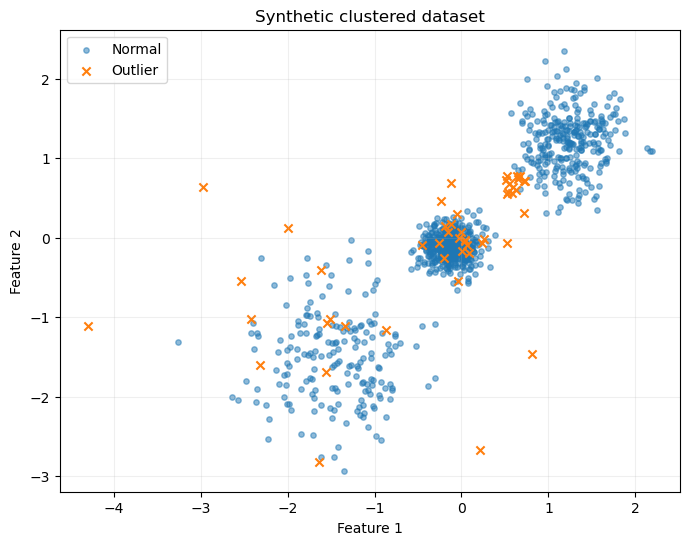

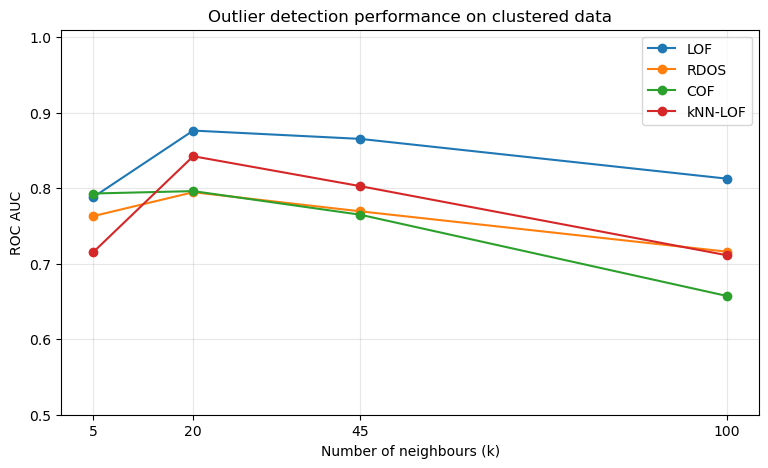

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.metrics import roc_auc_score, pairwise_distances


# ============================================================
# 1. kNN-LOF IMPLEMENTATION
# Xu et al. (2022), equations (7)-(11)
# ============================================================

def knn_lof(
    X,
    k=20,
    n_outliers=None,
    metric="euclidean",
    eq8_mode="mean",
    eps=1e-12
):
    X = np.asarray(X, dtype=float)

    if X.ndim != 2:
        raise ValueError("X must have shape (n_samples, n_features).")

    if not np.isfinite(X).all():
        raise ValueError("X contains NaN or infinite values.")

    n_samples = X.shape[0]

    if k < 2 or k >= n_samples:
        raise ValueError("k must satisfy 2 <= k < number of samples.")

    # --------------------------------------------------------
    # Find k nearest neighbours
    # --------------------------------------------------------

    nn = NearestNeighbors(
        n_neighbors=k + 1,
        metric=metric
    )

    nn.fit(X)

    all_distances, all_indices = nn.kneighbors(X)

    neighbors = np.empty((n_samples, k), dtype=int)
    distances = np.empty((n_samples, k), dtype=float)

    # Remove the observation itself
    for p in range(n_samples):

        mask = all_indices[p] != p

        neighbors[p] = all_indices[p][mask][:k]
        distances[p] = all_distances[p][mask][:k]

    # Distance to kth nearest neighbour
    k_distance = distances[:, -1]

    # --------------------------------------------------------
    # Equation (7): sequence distance
    # --------------------------------------------------------

    r = k + 1

    i = np.arange(2, r + 1)

    sequence_weights = (
        (r - i) / r
    )

    sequence_distance = (
        distances * sequence_weights
    ).sum(axis=1) / r

    # --------------------------------------------------------
    # Equation (8): average sequence distance
    # --------------------------------------------------------

    neighbour_sequence_distances = (
        sequence_distance[neighbors]
    )

    if eq8_mode == "mean":

        avg_sequence_distance = (
            neighbour_sequence_distances.mean(axis=1)
        )

    elif eq8_mode == "paper":

        avg_sequence_distance = (
            neighbour_sequence_distances.sum(axis=1)
            / np.maximum(k_distance, eps)
        )

    else:

        raise ValueError(
            "eq8_mode must be either 'mean' or 'paper'."
        )

    # --------------------------------------------------------
    # Equation (9): local neighbourhood density
    # --------------------------------------------------------

    local_density = (
        1.0
        / np.maximum(
            avg_sequence_distance,
            eps
        )
    )

    # --------------------------------------------------------
    # Equation (10): neighbourhood density
    # --------------------------------------------------------

    neighborhood_density = (
        local_density[neighbors].mean(axis=1)
    )

    # --------------------------------------------------------
    # Equation (11): NLOF score
    # --------------------------------------------------------

    scores = (
        neighborhood_density
        / np.maximum(
            local_density,
            eps
        )
    )

    # Higher score = more anomalous
    ranking = np.argsort(scores)[::-1]

    if n_outliers is None:

        outlier_indices = None

    else:

        if n_outliers < 1 or n_outliers > n_samples:

            raise ValueError(
                "n_outliers must be between 1 and n_samples."
            )

        outlier_indices = ranking[:n_outliers]

    return {
        "scores": scores,
        "ranking": ranking,
        "outlier_indices": outlier_indices,
        "neighbors": neighbors,
        "k_distance": k_distance,
        "sequence_distance": sequence_distance,
        "avg_sequence_distance": avg_sequence_distance,
        "local_density": local_density,
        "neighborhood_density": neighborhood_density
    }


# ============================================================
# 2. SYNTHETIC CLUSTERED DATASET
#
# Designed specifically to test local outlier detection:
#
# - dense cluster
# - medium-density cluster
# - sparse cluster
#
# Outliers occur:
#
# - near dense cluster boundaries
# - between clusters
# - around the sparse cluster
#
# This is more difficult than simply putting outliers far
# away from all normal observations.
# ============================================================

def make_knn_lof_dataset(
    n_samples=1000,
    contamination=0.05,
    n_features=6,
    random_state=42,
    scale=True
):
    rng = np.random.default_rng(random_state)

    # --------------------------------------------------------
    # Determine number of normal points and outliers
    # --------------------------------------------------------

    n_outliers = int(
        round(n_samples * contamination)
    )

    n_normal = (
        n_samples - n_outliers
    )

    # --------------------------------------------------------
    # Divide normal observations into three clusters
    # --------------------------------------------------------

    n_dense = int(
        n_normal * 0.50
    )

    n_medium = int(
        n_normal * 0.30
    )

    n_sparse = (
        n_normal
        - n_dense
        - n_medium
    )

    # --------------------------------------------------------
    # Cluster centres
    # --------------------------------------------------------

    center_dense = np.zeros(
        n_features
    )

    center_medium = np.zeros(
        n_features
    )

    center_medium[:2] = 3.0

    center_sparse = np.zeros(
        n_features
    )

    center_sparse[:2] = -3.0

    # --------------------------------------------------------
    # Dense cluster
    # --------------------------------------------------------

    dense_cluster = rng.normal(
        loc=center_dense,
        scale=0.35,
        size=(
            n_dense,
            n_features
        )
    )

    # --------------------------------------------------------
    # Medium-density cluster
    # --------------------------------------------------------

    medium_cluster = rng.normal(
        loc=center_medium,
        scale=0.75,
        size=(
            n_medium,
            n_features
        )
    )

    # --------------------------------------------------------
    # Sparse cluster
    # --------------------------------------------------------

    sparse_cluster = rng.normal(
        loc=center_sparse,
        scale=1.30,
        size=(
            n_sparse,
            n_features
        )
    )

    X_normal = np.vstack([
        dense_cluster,
        medium_cluster,
        sparse_cluster
    ])

    # ========================================================
    # CREATE LOCAL OUTLIERS
    # ========================================================

    # 40% near dense cluster boundary
    n_edge = int(
        n_outliers * 0.40
    )

    # 30% between clusters
    n_bridge = int(
        n_outliers * 0.30
    )

    # Remaining 30% near sparse cluster
    n_sparse_outliers = (
        n_outliers
        - n_edge
        - n_bridge
    )

    # --------------------------------------------------------
    # Type 1:
    # Boundary outliers around dense cluster
    # --------------------------------------------------------

    edge_outliers = rng.normal(
        loc=center_dense,
        scale=0.35,
        size=(
            n_edge,
            n_features
        )
    )

    for i in range(n_edge):

        feature = rng.integers(
            0,
            n_features
        )

        direction = rng.choice(
            [-1, 1]
        )

        edge_outliers[
            i,
            feature
        ] += (
            direction
            * rng.uniform(
                1.2,
                1.8
            )
        )

    # --------------------------------------------------------
    # Type 2:
    # Bridge outliers between dense and medium clusters
    # --------------------------------------------------------

    bridge_center = (
        center_dense
        + center_medium
    ) / 2

    bridge_outliers = rng.normal(
        loc=bridge_center,
        scale=0.30,
        size=(
            n_bridge,
            n_features
        )
    )

    # --------------------------------------------------------
    # Type 3:
    # Local outliers near sparse cluster
    # --------------------------------------------------------

    sparse_outliers = rng.normal(
        loc=center_sparse,
        scale=1.30,
        size=(
            n_sparse_outliers,
            n_features
        )
    )

    for i in range(n_sparse_outliers):

        features = rng.choice(
            n_features,
            size=2,
            replace=False
        )

        directions = rng.choice(
            [-1, 1],
            size=2
        )

        sparse_outliers[
            i,
            features
        ] += (
            directions
            * rng.uniform(
                2.0,
                3.0,
                size=2
            )
        )

    # --------------------------------------------------------
    # Combine all anomaly types
    # --------------------------------------------------------

    X_outliers = np.vstack([
        edge_outliers,
        bridge_outliers,
        sparse_outliers
    ])

    # --------------------------------------------------------
    # Combine normal observations and anomalies
    # --------------------------------------------------------

    X = np.vstack([
        X_normal,
        X_outliers
    ])

    y = np.concatenate([
        np.zeros(
            n_normal,
            dtype=int
        ),
        np.ones(
            n_outliers,
            dtype=int
        )
    ])

    # --------------------------------------------------------
    # Shuffle
    # --------------------------------------------------------

    permutation = rng.permutation(
        n_samples
    )

    X = X[permutation]
    y = y[permutation]

    # --------------------------------------------------------
    # Standardize features
    # --------------------------------------------------------

    if scale:

        X = StandardScaler().fit_transform(
            X
        )

    # --------------------------------------------------------
    # Convert to DataFrame
    # --------------------------------------------------------

    X = pd.DataFrame(
        X,
        columns=[
            f"feature_{i + 1}"
            for i in range(n_features)
        ]
    )

    return X, y


# ============================================================
# 3. COF
# Connectivity-Based Outlier Factor
# ============================================================

def cof_scores(
    distance_matrix,
    neighbors,
    k,
    eps=1e-12
):
    n_samples = (
        distance_matrix.shape[0]
    )

    Nk = neighbors[:, :k]

    chaining_distance = np.zeros(
        n_samples
    )

    # Chaining weights
    step = np.arange(
        1,
        k + 1
    )

    weights = (
        2 * (k + 1 - step)
        / (k * (k + 1))
    )

    for p in range(n_samples):

        candidates = Nk[p]

        min_to_chain = (
            distance_matrix[
                p,
                candidates
            ].copy()
        )

        visited = np.zeros(
            k,
            dtype=bool
        )

        edge_distances = np.empty(
            k
        )

        for j in range(k):

            available = np.flatnonzero(
                ~visited
            )

            nearest_position = available[
                np.argmin(
                    min_to_chain[
                        available
                    ]
                )
            ]

            new_point = candidates[
                nearest_position
            ]

            edge_distances[j] = (
                min_to_chain[
                    nearest_position
                ]
            )

            visited[
                nearest_position
            ] = True

            remaining = np.flatnonzero(
                ~visited
            )

            if remaining.size > 0:

                min_to_chain[
                    remaining
                ] = np.minimum(

                    min_to_chain[
                        remaining
                    ],

                    distance_matrix[
                        new_point,
                        candidates[
                            remaining
                        ]
                    ]
                )

        chaining_distance[p] = (
            weights
            * edge_distances
        ).sum()

    neighbour_chaining_distance = (
        chaining_distance[
            Nk
        ].mean(axis=1)
    )

    scores = (
        chaining_distance
        / np.maximum(
            neighbour_chaining_distance,
            eps
        )
    )

    return scores


# ============================================================
# 4. RDOS
# Relative Density-Based Outlier Score
# ============================================================

def rdos_scores(
    distance_matrix,
    neighbors,
    k,
    bandwidth=1.0,
    eps=1e-12
):
    n_samples = (
        distance_matrix.shape[0]
    )

    Nk = neighbors[:, :k]

    # --------------------------------------------------------
    # Reverse nearest neighbours
    # --------------------------------------------------------

    reverse_neighbors = [
        set()
        for _ in range(n_samples)
    ]

    for p in range(n_samples):

        for q in Nk[p]:

            reverse_neighbors[
                q
            ].add(p)

    # --------------------------------------------------------
    # Extended neighbourhoods
    # --------------------------------------------------------

    extended_neighbors = []

    for p in range(n_samples):

        neighborhood = set(
            Nk[p]
        )

        # Reverse neighbours
        neighborhood.update(
            reverse_neighbors[p]
        )

        # Shared-neighbour information
        for q in Nk[p]:

            neighborhood.update(
                reverse_neighbors[q]
            )

        neighborhood.discard(
            p
        )

        extended_neighbors.append(
            np.array(
                list(neighborhood),
                dtype=int
            )
        )

    # --------------------------------------------------------
    # Gaussian kernel
    # --------------------------------------------------------

    kernel = np.exp(
        -(distance_matrix ** 2)
        / (2 * bandwidth ** 2)
    )

    # --------------------------------------------------------
    # Local density
    # --------------------------------------------------------

    density = np.zeros(
        n_samples
    )

    for p in range(n_samples):

        neighborhood = (
            extended_neighbors[p]
        )

        density[p] = (
            1.0
            + kernel[
                p,
                neighborhood
            ].sum()
        ) / (
            len(neighborhood)
            + 1
        )

    # --------------------------------------------------------
    # RDOS score
    # --------------------------------------------------------

    scores = np.ones(
        n_samples
    )

    for p in range(n_samples):

        neighborhood = (
            extended_neighbors[p]
        )

        if len(neighborhood) > 0:

            scores[p] = (
                density[
                    neighborhood
                ].mean()
                / max(
                    density[p],
                    eps
                )
            )

    return scores


# ============================================================
# 5. CREATE CLUSTERED DATASET
# ============================================================

X, y = make_knn_lof_dataset(
    n_samples=1000,
    contamination=0.05,
    n_features=6,
    random_state=42
)

X_np = X.to_numpy()

print("Dataset information")
print("-------------------")
print("Shape:", X.shape)
print("Normal observations:", np.sum(y == 0))
print("Outliers:", np.sum(y == 1))
print("Outlier proportion:", y.mean())


# ============================================================
# 6. REPRESENTATIVE k VALUES
#
# 5   = small
# 20  = small-medium
# 45  = medium
# 100 = large
# ============================================================

k_values = [
    5,
    20,
    45,
    100
]


# ============================================================
# 7. PRECOMPUTE DISTANCES AND NEIGHBOURS
# ============================================================

max_k = max(
    k_values
)

distance_matrix = pairwise_distances(
    X_np,
    metric="euclidean"
)

# Separate matrix used only to find neighbours.
# Diagonal = infinity so a point cannot select itself.
neighbor_distance_matrix = (
    distance_matrix.copy()
)

np.fill_diagonal(
    neighbor_distance_matrix,
    np.inf
)

neighbors = np.argsort(
    neighbor_distance_matrix,
    axis=1
)[:, :max_k]


# ============================================================
# 8. RUN EXPERIMENT
# ============================================================

results = []

for k in k_values:

    print(
        f"\nRunning k = {k}..."
    )

    # --------------------------------------------------------
    # LOF
    # --------------------------------------------------------

    lof = LocalOutlierFactor(
        n_neighbors=k,
        metric="euclidean"
    )

    lof.fit(
        X_np
    )

    # sklearn uses negative LOF scores.
    # Reverse sign so higher = more anomalous.
    lof_score = (
        -lof.negative_outlier_factor_
    )

    # --------------------------------------------------------
    # kNN-LOF
    # --------------------------------------------------------

    knnlof_result = knn_lof(
        X_np,
        k=k,
        metric="euclidean",
        eq8_mode="mean"
    )

    knnlof_score = (
        knnlof_result[
            "scores"
        ]
    )

    # --------------------------------------------------------
    # COF
    # --------------------------------------------------------

    cof_score = cof_scores(
        distance_matrix,
        neighbors,
        k
    )

    # --------------------------------------------------------
    # RDOS
    # --------------------------------------------------------

    rdos_score = rdos_scores(
        distance_matrix,
        neighbors,
        k,
        bandwidth=1.0
    )

    # --------------------------------------------------------
    # Calculate ROC AUC
    # --------------------------------------------------------

    results.append({
        "k": k,

        "LOF": roc_auc_score(
            y,
            lof_score
        ),

        "RDOS": roc_auc_score(
            y,
            rdos_score
        ),

        "COF": roc_auc_score(
            y,
            cof_score
        ),

        "kNN-LOF": roc_auc_score(
            y,
            knnlof_score
        )
    })


# ============================================================
# 9. RESULTS TABLE
# ============================================================

results = pd.DataFrame(
    results
)

print(
    "\n\nROC AUC RESULTS"
)

print(
    "===============\n"
)

print(
    results
    .round(4)
    .to_string(
        index=False
    )
)


# ============================================================
# 10. BEST RESULT FOR EACH ALGORITHM
# ============================================================

print(
    "\nBest result per algorithm"
)

print(
    "-------------------------"
)

for algorithm in [
    "LOF",
    "RDOS",
    "COF",
    "kNN-LOF"
]:

    best_index = (
        results[
            algorithm
        ].idxmax()
    )

    best_auc = (
        results.loc[
            best_index,
            algorithm
        ]
    )

    best_k = int(
        results.loc[
            best_index,
            "k"
        ]
    )

    print(
        f"{algorithm:8s}: "
        f"AUC = {best_auc:.4f}, "
        f"k = {best_k}"
    )


# ============================================================
# 11. IDENTIFY BEST ALGORITHM AT EACH k
# ============================================================

print(
    "\nBest algorithm for each k"
)

print(
    "-------------------------"
)

algorithm_columns = [
    "LOF",
    "RDOS",
    "COF",
    "kNN-LOF"
]

for _, row in results.iterrows():

    best_algorithm = row[
        algorithm_columns
    ].idxmax()

    best_auc = row[
        best_algorithm
    ]

    print(
        f"k = {int(row['k']):3d}: "
        f"{best_algorithm} "
        f"(AUC = {best_auc:.4f})"
    )


# ============================================================
# 12. VISUALISE DATASET
#
# Only the first two dimensions are shown.
# This is for visual inspection; all six dimensions are used
# by the outlier detection algorithms.
# ============================================================

plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    X_np[y == 0, 0],
    X_np[y == 0, 1],
    s=15,
    alpha=0.5,
    label="Normal"
)

plt.scatter(
    X_np[y == 1, 0],
    X_np[y == 1, 1],
    s=35,
    marker="x",
    label="Outlier"
)

plt.xlabel(
    "Feature 1"
)

plt.ylabel(
    "Feature 2"
)

plt.title(
    "Synthetic clustered dataset"
)

plt.legend()

plt.grid(
    alpha=0.2
)

plt.show()


# ============================================================
# 13. PLOT AUC PERFORMANCE
# ============================================================

plt.figure(
    figsize=(9, 5)
)

for algorithm in [
    "LOF",
    "RDOS",
    "COF",
    "kNN-LOF"
]:

    plt.plot(
        results["k"],
        results[algorithm],
        marker="o",
        label=algorithm
    )

plt.xlabel(
    "Number of neighbours (k)"
)

plt.ylabel(
    "ROC AUC"
)

plt.title(
    "Outlier detection performance on clustered data"
)

plt.xticks(
    k_values
)

plt.ylim(
    0.5,
    1.01
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()